**Navigation** : [Index](../../README.md) | [<< Precedent](02-5-Bonsai-Image-Ternary.ipynb)

# 02-6 - Modeles generatifs few-step : IMM et TVM

## Generer une image en un seul pas

Les carnets precedents de la serie font tous appel au meme mecanisme : un modele de diffusion **itere** un estimateur de bruit des dizaines de fois ([02-2 FLUX](02-2-FLUX-1-Advanced-Generation.ipynb), [02-3 SD 3.5](02-3-Stable-Diffusion-3-5.ipynb), [02-4 Z-Image](02-4-Z-Image-Lumina2.ipynb)). Chaque iteration coute un passage dans le reseau ; sur un modele de plusieurs milliards de parametres, c'est le poste dominant du temps de calcul.

Deux travaux recents de Luma AI et Stanford attackent ce point : **Inductive Moment Matching** ([IMM](https://arxiv.org/abs/2503.07565), ICML 2025) et **Terminal Velocity Matching** ([TVM](https://arxiv.org/abs/2511.19797)). Leur promesse tient en une phrase : *un modele entraine pour cela produit une image de qualite publication en un, deux ou quatre appels de reseau*.

Ce carnet **mesure** cette promesse au lieu de la repeter :

- le **code officiel** des deux depots est execute (rien n'est reimplemente) ;
- les **poids officiels** sont charges (`lumaai/imm:cifar10.pt`, `lumaai/tvm:im256_w2.pkl`, `lumaai/tvm:im256_w1p75.pkl`) ;
- la **qualite est calculee** avec le code de metrique officiel (detecteur InceptionV3 de NVIDIA, distance de Frechet) ;
- le **biais d'echantillonnage du FID** est quantifie puis retire, ce qui permet de comparer la mesure aux **valeurs publiees** ;
- le compromis **nombre d'etapes / qualite / latence** est mesure, pas cite.

### Sources et licences

| Ressource | Adresse | Licence | Role ici |
|---|---|---|---|
| IMM (papier) | arXiv:2503.07565 | - | methode, chiffres publies |
| IMM (code) | `github.com/lumalabs/imm` | CC BY-NC-SA 4.0 | **execute**, jamais recopie ici |
| IMM (poids) | `huggingface.co/lumaai/imm` | CC BY-NC-SA 4.0 | `cifar10.pt` |
| TVM (papier) | arXiv:2511.19797 | - | methode, chiffres publies |
| TVM (code) | `github.com/lumalabs/tvm` | CC BY-NC-SA 4.0 | **execute**, jamais recopie ici |
| TVM (poids) | `huggingface.co/lumaai/tvm` | CC BY-NC-SA 4.0 | `im256_w2.pkl`, `im256_w1p75.pkl`, `dataset-refs/img256.pkl` |
| Detecteur InceptionV3 | NVIDIA stylegan3 | NVIDIA NC | calcul du FID |

**Les deux depots officiels sont sous CC BY-NC-SA 4.0** (non commercial, partage a l'identique). Conformement a [organ-first-implementation](../../../../.claude/rules/organ-first-implementation.md), **aucun code officiel n'est recopie dans CoursIA** : le carnet *clone* les depots a un commit fige dans un cache utilisateur et les importe a l'execution. Ce qui est livre ici, c'est la **mesure**.

### Ce qu'il faut

- un GPU NVIDIA (mesure ici sur une **RTX 3070 Ti 8 Go**) ;
- du reseau pour le premier lancement (~6 Go : deux depots, les poids officiels, les statistiques de reference et le jeu CIFAR-10) ;
- environ 1 h 30 de calcul pour la premiere execution complete (les statistiques sont **mises en cache** : une re-execution relit le cache et ne remesure que la latence).


In [1]:
import hashlib
import os
import pickle
import subprocess
import sys
import time
import urllib.request
from pathlib import Path

import numpy as np
import torch

CACHE = Path(os.environ.get("COURSIA_FEWSTEP_CACHE", Path.home() / ".cache" / "coursia-fewstep"))
REPOS_DIR, MODELS_DIR, STATS_DIR = CACHE / "repos", CACHE / "models", CACHE / "stats"
for _d in (REPOS_DIR, MODELS_DIR, STATS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# Le code officiel (dnnlib) telecharge ses propres artefacts dans un cache dedie.
# On le redirige vers le cache du carnet pour que tout reste au meme endroit.
os.environ["DNNLIB_CACHE_DIR"] = str(CACHE / "dnnlib")

# Depots officiels : clone au commit fige, aucun code officiel recopie dans CoursIA.
OFFICIAL_REPOS = {
    "imm": {"url": "https://github.com/lumalabs/imm.git", "commit": "e124a9d40ffa4ace9680a0bbbae6894e2fabc250"},
    "tvm": {"url": "https://github.com/lumalabs/tvm.git", "commit": "331c01d5dab02b795ad74bb67ee1c52b6a41abd4"},
}

# Artefacts officiels : poids et statistiques de reference.
OFFICIAL_ASSETS = {
    "imm_cifar10.pt": "https://huggingface.co/lumaai/imm/resolve/main/cifar10.pt",
    # im256_w2.pkl : CFG 2.0, 1 pas  -> FID publie 3.29
    "tvm_im256_w2.pkl": "https://huggingface.co/lumaai/tvm/resolve/main/im256_w2.pkl",
    # im256_w1p75.pkl : CFG 1.75, 4 pas -> FID publie 1.99
    "tvm_im256_w1p75.pkl": "https://huggingface.co/lumaai/tvm/resolve/main/im256_w1p75.pkl",
    "tvm_img256_ref_stats.pkl": "https://huggingface.co/lumaai/tvm/resolve/main/dataset-refs/img256.pkl",
    # Miroir Hugging Face du jeu CIFAR-10 d'origine. Le serveur canonique
    # (cs.toronto.edu) est dessert a ~50 ko/s depuis cette machine ; les images
    # sont rigoureusement les memes.
    "cifar10_train.parquet": "https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/train-00000-of-00001.parquet",
}

# Detecteur de features InceptionV3 officiel (NVIDIA) : c'est lui que le code de
# metrique officiel charge pour calculer le FID.
DETECTOR_URL = "https://api.ngc.nvidia.com/v2/models/nvidia/research/stylegan3/versions/1/files/metrics/inception-2015-12-05.pkl"


def _download(url, dest):
    """Telechargement avec progression, ecrit dans un fichier temporaire hors du
    cache dnnlib (dont la convention de nom est un glob strict)."""
    tmp = MODELS_DIR / (dest.name + ".part")
    req = urllib.request.Request(url, headers={"User-Agent": "CoursIA/02-6"})
    with urllib.request.urlopen(req, timeout=900) as r, open(tmp, "wb") as f:
        while True:
            chunk = r.read(1 << 22)
            if not chunk:
                break
            f.write(chunk)
    tmp.replace(dest)


def ensure_repo(name):
    """Clone le depot officiel au commit fige (une seule fois) et renvoie son chemin."""
    spec = OFFICIAL_REPOS[name]
    dest = REPOS_DIR / name
    if not (dest / ".git").exists():
        subprocess.run(["git", "clone", "--quiet", spec["url"], str(dest)], check=True)
    subprocess.run(["git", "-C", str(dest), "checkout", "--quiet", spec["commit"]], check=True)
    return dest


def ensure_asset(filename):
    """Telecompose un artefact officiel dans le cache (idempotent)."""
    dest = MODELS_DIR / filename
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    print(f"telechargement de {filename} ...", flush=True)
    _download(OFFICIAL_ASSETS[filename], dest)
    return dest


def ensure_detector():
    """Depose le detecteur officiel dans le cache de dnnlib, sous le nom exact que
    dnnlib.util.open_url attend (md5 de l'URL + nom de fichier) : le code officiel
    trouve ainsi le fichier deja telecharge et ne retelecharge pas 95 Mo a chaque run."""
    target_dir = CACHE / "dnnlib" / "downloads"
    target_dir.mkdir(parents=True, exist_ok=True)
    digest = hashlib.md5(DETECTOR_URL.encode("utf-8")).hexdigest()
    target = target_dir / f"{digest}_inception-2015-12-05.pkl"
    if target.exists() and target.stat().st_size > 0:
        return target
    print("telechargement du detecteur InceptionV3 officiel ...", flush=True)
    _download(DETECTOR_URL, target)
    return target


REPO_PATHS = {name: ensure_repo(name) for name in OFFICIAL_REPOS}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("python       :", sys.version.split()[0])
print("torch        :", torch.__version__)
print("GPU          :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("cache        :", CACHE)
print("depots       :", {k: v.name for k, v in REPO_PATHS.items()})


python       : 3.10.22
torch        : 2.8.0+cu126
GPU          : NVIDIA GeForce RTX 3070 Ti Laptop GPU
cache        : C:\Users\jsboi\.cache\coursia-fewstep
depots       : {'imm': 'imm', 'tvm': 'tvm'}


## 1. Theorie : pourquoi un seul pas est possible

### 1.1 Le cout d'une diffusion classique

Un modele de diffusion apprend a **renverser** un processus de destruction progressive du signal. On part d'un bruit gaussien et on reintegre progressivement la structure ; chaque integration demande une evaluation du reseau entraine a estimer le bruit a un niveau de bruit donne. Pour 32 a 50 pas, on execute donc 32 a 50 fois le meme reseau.

### 1.2 IMM - Inductive Moment Matching

[IMM](https://arxiv.org/abs/2503.07565) (Zhou, Ermon, Song) ne cherche pas a accelerer un modele de diffusion : il **entraine un modele qui, des le depart, est un modele a une etape**. L'idee est que la fonction de denoising peut s'apprendre comme la **projection d'un ecart de moment** : on apprend a faire correspondre, a chaque niveau de bruit, la **conditionnelle** de la donnee reelle et un modele genere. L'entrainement est celui d'un modele de diffusion classique ; c'est la **cible** qui change.

Concretement, un modele IMM de type SongUNet (DDPM++) Conditionne sur le niveau de bruit `t` et expose un pas de debruillage **continu** : l'ecart entre l'etat bruite et l'etat denbruite est predit par un champ de vitesse. Echantillonner en `N` pas revient a integrer ce champ `N` fois sur l'intervalle de bruit `[T, eps]`.

### 1.3 TVM - Terminal Velocity Matching

[TVM](https://arxiv.org/abs/2511.19797) (Zhou, Parger, Haque, Song) part du meme constat et le pousse plus loin : si l'on sait deja que l'ecart de moment doit s'annuler en `t = 0` (la **velocity terminale** du processus de destruction est nulle), on peut **extrapoler** le champ de vitesse jusqu'a zero au lieu de l'integrer pas a pas. On passe alors d'un schema d'integration a un schema d'**extrapolation** : le nombre d'evaluations du reseau devient un hyperparametre libre, et 1 pas devient possible.

TVM travaille dans l'espace latent d'un VAE (Stable Diffusion) sur ImageNet-256, avec un DiT-XL/2 et un **guidage de classe** (CFG) dont l'echelle est un hyperparametre du modele.

### 1.4 Ce que l'on va mesurer

| Grandeur | Definition | Outil officiel utilise |
|---|---|---|
| **NFE** | nombre d'evaluations du reseau de generation | compteur de la boucle d'echantillonnage officielle |
| **FID** | distance de Frechet entre les features InceptionV3 des images generees et celles des images reelles | `calculate_metrics.py` du depot officiel + detecteur NVIDIA |
| **biais** | ecart systematique du FID impose par la taille d'echantillon | estimation depuis les statistiques de reference + controle empirique sur images reelles |
| **latence** | secondes par image generee, materiel de reference | chronometre autour de la generation + du decodage |

Le **NFE** est l'axe pedagogique central : c'est lui qui, dans la pratique, decide si un modele tient dans un budget de latence. Le **FID** est l'axe de qualite : il doit rester faible quand le NFE baisse.

> **Attention a la lecture du FID.** Un FID n'est comparable a un autre que si le jeu de reference, le detecteur et la taille d'echantillon sont identiques. Les chiffres publies par IMM et TVM sont calcules sur **50 000** images ; un FID mesure sur moins d'echantillons est **systematiquement plus grand**, parce que la covariance empirique des features (2048 dimensions) est alors deficientaire en rang. Ce carnet ne se contente pas de constater l'ecart : il **quantifie** ce biais (fonction `sampling_bias`) et le **retire** des valeurs mesurees, ce qui rend la comparaison avec les valeurs publiees possible. Le retrait est legitime parce que le biais ne depend que de la reference et du nombre d'echantillons, **pas du modele** : il est donc commun a toutes les configurations comparees, et les differences entre configurations, elles, ne sont pas affectees.


In [2]:
import torch.distributed as torch_dist

# L'API officielle de calcul des statistiques communique entre GPU via torch.distributed
# (reduction des accumulateurs, barrieres de synchronisation). En mono-processus ces
# operations sont l'identite ; or le backend gloo n'est pas disponible sur cette machine
# (Windows). On les neutralise donc : les statistiques produites sont exactement celles
# d'une execution mono-GPU, c'est-a-dire celles d'un `torchrun` a world_size=1.
if not torch_dist.is_initialized():
    torch_dist.all_reduce = lambda tensor, *args, **kwargs: tensor
    torch_dist.barrier = lambda *args, **kwargs: None


def activate_repo(name):
    """Les deux depots officiels exposent les memes noms de paquets (`training`, `dnnlib`,
    `metrics`...) et les memes modules (`calculate_metrics`, `generate_images`).
    On reinitialise donc les modules deja importes avant de basculer d'un depot a l'autre,
    sinon Python reutiliserait le paquet du mauvais depot."""
    for mod in list(sys.modules):
        if mod.split(".")[0] in {"training", "torch_utils", "dnnlib", "metrics",
                                 "calculate_metrics", "generate_images"}:
            del sys.modules[mod]
    for path in list(sys.path):
        if path in {str(p) for p in REPO_PATHS.values()}:
            sys.path.remove(path)
    sys.path.insert(0, str(REPO_PATHS[name]))


activate_repo("imm")

import dnnlib
from torch_utils import misc
from training.encoders import StandardRGBEncoder

# Configuration officielle : configs/cifar10_generate_images.yaml du depot lumalabs/imm.
IMM_NETWORK_KWARGS = dict(
    class_name="training.preconds.IMMPrecond",
    model_type="SongUNet",
    embedding_type="positional",
    encoder_type="standard",
    decoder_type="standard",
    channel_mult_noise=1,
    resample_filter=[1, 1],
    model_channels=128,
    channel_mult=[2, 2, 2],
    s_embed=True,
    dropout=0.2,
    noise_schedule="fm",
    f_type="simple_edm",
    temb_type="identity",
    time_scale=1000,
    eps=0.006,
    T=0.994,
)

IMM_CKPT = ensure_asset("imm_cifar10.pt")
imm_net = dnnlib.util.construct_class_by_name(
    **IMM_NETWORK_KWARGS, img_resolution=32, img_channels=3, label_dim=0
)
imm_net.eval().requires_grad_(False).to(DEVICE)
with open(IMM_CKPT, "rb") as f:
    imm_ckpt = pickle.load(f)
misc.copy_params_and_buffers(src_module=imm_ckpt["ema"], dst_module=imm_net, require_all=True)
imm_encoder = StandardRGBEncoder()

print(f"IMMPrecond / SongUNet : {sum(p.numel() for p in imm_net.parameters()) / 1e6:.1f} M parametres")
print(f"resolution={imm_net.img_resolution} | T={imm_net.T} | eps={imm_net.eps} | label_dim={imm_net.label_dim}")
print("checkpoint officiel :", IMM_CKPT.name)


C:\Users\jsboi\miniconda3\envs\coursia-ml-training-py310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Mparams: 56.061443


IMMPrecond / SongUNet : 56.1 M parametres
resolution=32 | T=0.994 | eps=0.006 | label_dim=0
checkpoint officiel : imm_cifar10.pt


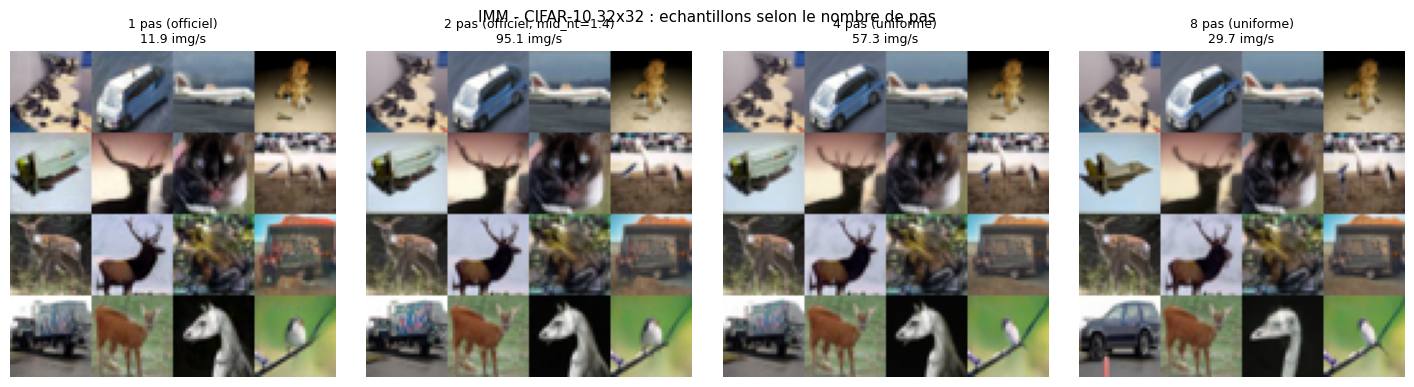

In [3]:
import matplotlib.pyplot as plt

from generate_images import pushforward_generator_fn

IMM_RESOLUTION = 32

# Schedules d'echantillonnage du depot officiel (configs/cifar10_generate_images.yaml).
#   1_step  : mid_nt absent     -> une seule transition, de T a eps
#   2_steps : mid_nt = [1.4]    -> deux transitions, point intermediaire officiel
# La discretisation uniforme n'est PAS dans la configuration officielle : on l'utilise
# pour les schedules a 4 et 8 pas, et on la signale comme extension du code officiel.
IMM_SCHEDULES = [
    {"label": "1 pas (officiel)", "nfe": 1, "discretization": None, "mid_nt": None},
    {"label": "2 pas (officiel, mid_nt=1.4)", "nfe": 2, "discretization": None, "mid_nt": [1.4]},
    {"label": "4 pas (uniforme)", "nfe": 4, "discretization": "uniform", "mid_nt": None},
    {"label": "8 pas (uniforme)", "nfe": 8, "discretization": "uniform", "mid_nt": None},
]


def to_grid(images, side=4):
    """Assemble en grille side x side des images NCHW."""
    arr = images[: side * side].detach().cpu()
    if arr.dtype != torch.uint8:
        arr = arr.clamp(0, 255).to(torch.uint8)
    arr = arr.numpy().transpose(0, 2, 3, 1)  # (N, H, W, C)
    h, w, c = arr.shape[1:]
    arr = arr.reshape(side, side, h, w, c).transpose(0, 2, 1, 3, 4)
    return arr.reshape(side * h, side * w, c)


def imm_sample(n, num_steps, mid_nt=None, discretization=None, seed=42, batch_size=256):
    """Genere n images CIFAR-10 avec la boucle d'echantillonnage officielle.
    Retourne (images NCHW uint8, duree en secondes)."""
    torch.manual_seed(seed)
    chunks, t0 = [], time.time()
    with torch.no_grad():
        for start in range(0, n, batch_size):
            size = min(batch_size, n - start)
            z = imm_net.get_init_noise([size, 3, IMM_RESOLUTION, IMM_RESOLUTION], DEVICE)
            latents = pushforward_generator_fn(
                imm_net, z, None,
                discretization=discretization, num_steps=num_steps, mid_nt=mid_nt,
            )
            decoded = imm_encoder.decode(latents.to(DEVICE)).detach().cpu()
            chunks.append(decoded if decoded.dtype == torch.uint8 else decoded.clamp(0, 255).to(torch.uint8))
    return torch.cat(chunks), time.time() - t0


fig, axes = plt.subplots(1, len(IMM_SCHEDULES), figsize=(3.6 * len(IMM_SCHEDULES), 3.9))
for ax, sched in zip(axes, IMM_SCHEDULES):
    images, dt = imm_sample(16, sched["nfe"], mid_nt=sched["mid_nt"], discretization=sched["discretization"])
    ax.imshow(to_grid(images))
    ax.set_title(f"{sched['label']}\n{16 / dt:.1f} img/s", fontsize=9)
    ax.axis("off")
fig.suptitle("IMM - CIFAR-10 32x32 : echantillons selon le nombre de pas", fontsize=11)
fig.tight_layout()
plt.show()


### Lecture du resultat : l'ecart se voit avant meme la mesure

Les quatre planches sont produites a partir du **meme tirage de bruit** (graine identique, meme checkpoint) : seule l'**echelle de discretisation** change. C'est ce qui rend la comparaison lisible : ce que l'on voit d'une planche a l'autre est l'effet du schedule, pas un nouvel echantillonnage.

Ce que l'on regarde :

- **a 1 pas**, les images sont formees et coherentes, mais **plus lisses** : le modele n'a fait qu'une seule estimation, il a rendu une image plausible plutot qu'un echantillon tire ;
- **a 2 pas**, la structure se precise : la premiere estimation posait la forme, la seconde corrige ;
- **a 4 et 8 pas**, le gain devient marginal : le modele a surtout affine ce qui etait deja la.

Le debit affiche sous chaque planche est une **indication** : il est calcule sur 16 images, echauffement compris. La mesure qui fait foi est la colonne `ms/image` du tableau de la section suivante, qui distingue en outre le cout du **reseau** de celui du **decodeur**. La suite du carnet mesure ce que ces differences de texture coutent en **FID**, sur un echantillon de taille serieuse.

> **Ce qui est officiel, et ce qui ne l'est pas.** Les schedules a 1 et 2 pas sont ceux de la configuration officielle du depot (`configs/cifar10_generate_images.yaml` : `mid_nt: null` pour 1 pas, `mid_nt: [1.4]` pour 2 pas). Il n'existe **pas** de schedule officiel a 4 ou 8 pas : ces deux planches utilisent la discretisation **uniforme** proposee par le code officiel, qui est une **extension**, pas la configuration des auteurs. Elles servent a etablir la forme de la courbe, pas a comparer au papier.


In [4]:
import numpy as np
import scipy.linalg

# Note sur le backend distribue : la boucle de statistiques officielle depose ses
# accumulateurs sur plusieurs GPU via torch.distributed. En mono-processus cette
# reduction est l'identite ; or le backend gloo n'est pas disponible sur cette machine
# (Windows) et l'appel echouerait sur "Default process group has not been initialized".
# Ces deux appels ont donc ete neutralises dans la cellule de chargement (cellule 3) :
# les statistiques produites sont exactement celles d'une execution mono-GPU, c'est-a-dire
# celles d'un `torchrun` a world_size=1. Aucun code officiel n'est modifie.


class BatchIterable:
    """Iterable de lots d'images NCHW uint8, avec la longueur qu'exige l'API officielle
    (elle s'en sert pour dimensionner sa boucle de reduction)."""

    def __init__(self, n, batch_size, factory):
        self.n, self.batch_size, self.factory = n, batch_size, factory

    def __len__(self):
        return (self.n + self.batch_size - 1) // self.batch_size

    def __iter__(self):
        for start in range(0, self.n, self.batch_size):
            yield self.factory(start, min(self.batch_size, self.n - start))


def frechet_distance(mu1, sigma1, mu2, sigma2):
    """Distance de Frechet entre deux lois gaussiennes. La formule est identique a celle
    du code officiel (metrics/frechet_inception_distance.py)."""
    m = np.square(mu2 - mu1).sum()
    s, _ = scipy.linalg.sqrtm(np.dot(sigma2, sigma1), disp=False)
    return float(np.real(m + np.trace(sigma2 + sigma1 - s * 2)))


def feature_stats(image_iter, metric_module):
    """Statistiques de features Inception d'un iterable d'images, via le code officiel."""
    last = None
    for last in metric_module.calculate_stats_for_iterable(
        image_iter, metrics=["fid"], verbose=False, device=DEVICE
    ):
        pass
    return last.stats["fid"]["mu"], last.stats["fid"]["sigma"]


def cached_stats(tag, builder):
    """Calcule les statistiques une seule fois, puis les relit depuis le cache disque
    (une re-execution du carnet ne recalcule pas 50 000 passes de detecteur)."""
    path = STATS_DIR / f"{tag}.npz"
    if path.exists():
        data = np.load(path)
        return data["mu"], data["sigma"]
    mu, sigma = builder()
    np.savez(path, mu=mu, sigma=sigma)
    return mu, sigma


def sampling_bias(mu, sigma, n, seed=0):
    """Biais d'echantillonnage attendu d'un FID calcule sur n images.

    Le FID compare deux covariances empiriques. Lorsque n reste inferieur a la
    dimension des features Inception (2048), la covariance empirique est deficientaire
    en rang : le FID mesure est alors surestime, independamment de la qualite du
    modele. On estime ce biais directement a partir des statistiques de reference : on
    tire n vecteurs de features gaussiens de loi N(mu, Sigma) et on calcule le FID
    contre la population. Un modele parfait y donnerait 0 : l'ecart mesure est donc
    le seul biais d'echantillonnage a ce n.
    """
    rng = np.random.default_rng(seed)
    dim = mu.shape[0]
    try:
        L = np.linalg.cholesky(sigma)
    except np.linalg.LinAlgError:
        L = np.linalg.cholesky(sigma + 1e-6 * np.eye(dim))
    # cholesky donne L tel que L @ L.T = sigma ; pour des echantillons en LIGNE
    # (z @ M) la covariance vaut M.T @ M : il faut donc M = L.T.
    x = rng.standard_normal((n, dim)) @ L.T + mu
    mu_s, sigma_s = x.mean(axis=0), np.cov(x, rowvar=False)
    return frechet_distance(mu, sigma, mu_s, sigma_s)


import calculate_metrics as imm_metrics

ensure_detector()
print("harnais de mesure pret : detecteur InceptionV3 officiel, formule FID officielle")


harnais de mesure pret : detecteur InceptionV3 officiel, formule FID officielle


In [5]:
import io

import pandas as pd

N_IMM = int(os.environ.get("COURSIA_FEWSTEP_N_IMM", "10000"))
N_REF = int(os.environ.get("COURSIA_FEWSTEP_N_REF", "50000"))

# Les deux fichiers du jeu sont telecharges explicitement : le cache n'est pas livre
# avec le depot, une execution sur une machine vierge doit donc les obtenir elle-meme.
ensure_asset("cifar10_train.parquet")
ensure_asset("cifar10_test.parquet")


def load_cifar10_split(split):
    """Jeu CIFAR-10 en uint8 (N, 32, 32, 3) pour le split demande (train ou test).

    Source : miroir Hugging Face du jeu canonique (memes images ; le serveur d'origine
    cs.toronto.edu est dessert a ~50 ko/s depuis cette machine)."""
    path = CACHE / f"cifar10_{split}.npy"
    if path.exists():
        return np.load(path)
    import pyarrow.parquet as pq
    from PIL import Image

    records = pq.read_table(MODELS_DIR / f"cifar10_{split}.parquet").column("img").to_pylist()
    out = np.zeros((len(records), 32, 32, 3), dtype=np.uint8)
    for i, rec in enumerate(records):
        out[i] = np.asarray(Image.open(io.BytesIO(rec["bytes"])).convert("RGB"))
    np.save(path, out)
    return out


def imm_real_batches(n, split="train", batch_size=250):
    images = load_cifar10_split(split)

    def factory(start, size):
        return torch.from_numpy(images[start:start + size]).permute(0, 3, 1, 2).contiguous()

    return BatchIterable(n, batch_size, factory)


def imm_gen_batches(n, num_steps, mid_nt=None, discretization=None, seed=42,
                    batch_size=250, timer=None):
    """Lots d'images generees par IMM.

    La graine ne depend que du debut du lot : tous les schedules demarrent donc du MEME
    bruit (variables communes), ce qui rend les differences de FID interpretables comme
    un effet du schedule et non comme un effet du tirage."""

    def factory(start, size):
        torch.manual_seed(seed + start)
        z = imm_net.get_init_noise([size, 3, IMM_RESOLUTION, IMM_RESOLUTION], DEVICE)
        t0 = time.perf_counter()
        latents = pushforward_generator_fn(
            imm_net, z, None,
            discretization=discretization, num_steps=num_steps, mid_nt=mid_nt,
        )
        t1 = time.perf_counter()
        images = imm_encoder.decode(latents.to(DEVICE)).detach().cpu()
        t2 = time.perf_counter()
        if timer is not None:
            timer["reseau"] = timer.get("reseau", 0.0) + (t1 - t0)
            timer["decodeur"] = timer.get("decodeur", 0.0) + (t2 - t1)
        return images

    return BatchIterable(n, batch_size, factory)


def measure_imm_latency(n_images, num_steps, mid_nt=None, discretization=None,
                         seed=1234, batch_size=250):
    """Latence de bout en bout, en ms/image, repartie entre le reseau et le decodeur.

    Le passage du detecteur Inception coute le meme quelle que soit la configuration :
    l'attribuer au modele fausserait la comparaison. On mesure donc la generation
    seule, apres un lot d'echauffement (le contexte CUDA doit s'initialiser, et ce
    cout n'est pas recurrent)."""
    timer = {}
    batches = iter(imm_gen_batches(n_images, num_steps, mid_nt=mid_nt,
                                   discretization=discretization, seed=seed,
                                   batch_size=batch_size, timer=timer))
    next(batches, None)
    timer.clear()
    start, counted = time.perf_counter(), 0
    for images in batches:
        counted += images.shape[0]
    total = time.perf_counter() - start
    return {
        "ms/image": 1000 * total / counted,
        "ms/image (reseau)": 1000 * timer.get("reseau", 0.0) / counted,
        "ms/image (decodeur)": 1000 * timer.get("decodeur", 0.0) / counted,
    }


print(f"reference reelle  : {N_REF} images CIFAR-10 (jeu d'entrainement complet)", flush=True)
print(f"echantillon genere : {N_IMM} images par configuration", flush=True)

ref_mu, ref_sigma = cached_stats(
    f"imm_cifar10_ref_n{N_REF}",
    lambda: feature_stats(imm_real_batches(N_REF), imm_metrics),
)
print("statistiques de reference calculees", flush=True)

# --- Verification de la disjointion des deux splits ------------------------------
# Le controle juste (ci-dessous) suppose que le jeu de test ne figure pas dans la
# reference. On ne l'affirme pas : on le verifie sur les pixels eux-memes.
def _empreinte_pixels(image):
    return hashlib.md5(np.ascontiguousarray(image).tobytes()).hexdigest()


_images_train = load_cifar10_split("train")
_images_test = load_cifar10_split("test")
_empreintes_train = {_empreinte_pixels(_images_train[i]) for i in range(len(_images_train))}
_empreintes_test = {_empreinte_pixels(_images_test[i]) for i in range(len(_images_test))}
_intersection = _empreintes_train & _empreintes_test
print(f"disjointion des splits : {len(_empreintes_train)} images distinctes dans train, "
      f"{len(_empreintes_test)} dans test, intersection = {len(_intersection)}", flush=True)
assert not _intersection, "le jeu de test n'est pas disjoint de la reference"
del _images_train, _images_test, _empreintes_train, _empreintes_test, _intersection

# --- Trois mesures du biais d'echantillonnage ------------------------------------
# (a) ESTIMATION : a partir des statistiques de reference, on tire N vecteurs de
#     features gaussiens de loi N(mu, Sigma) et on calcule le FID contre la population.
#     Un modele parfait y donnerait exactement 0 : l'ecart mesure est donc le seul
#     biais d'echantillonnage a ce N.
# (b) CONTROLE OPTIMISTE : un sous-ensemble de la reference mesure contre elle-meme.
#     Ce controle SOUS-ESTIME le biais : les images mesurees figurent aussi dans la
#     reference, et la distance entre deux lois empiriques qui se partagent leurs
#     echantillons est plus petite que celle de deux echantillons independants.
# (c) CONTROLE JUSTE : le jeu de TEST de CIFAR-10, DISJOINT de la reference (qui est
#     le jeu d'entrainement complet, disjointion verifiee ci-dessus). Ses 10 000 images
#     sont un echantillon independant de taille N : le FID qui les oppose a la
#     reference EST le biais d'echantillonnage, mesure sur des images reelles.
bias_estime = sampling_bias(ref_mu, ref_sigma, N_IMM)
sub_mu, sub_sigma = cached_stats(
    f"imm_cifar10_reel_n{N_IMM}",
    lambda: feature_stats(imm_real_batches(N_IMM), imm_metrics),
)
biais_sous_ensemble = frechet_distance(ref_mu, ref_sigma, sub_mu, sub_sigma)
test_mu, test_sigma = cached_stats(
    f"imm_cifar10_test_n{N_IMM}",
    lambda: feature_stats(imm_real_batches(N_IMM, split="test"), imm_metrics),
)
biais_controle = frechet_distance(ref_mu, ref_sigma, test_mu, test_sigma)
print(f"biais d'echantillonnage a N={N_IMM} : {bias_estime:.3f} (estime depuis la reference) "
      f"/ {biais_sous_ensemble:.3f} (controle optimiste : sous-ensemble de la reference) "
      f"/ {biais_controle:.3f} (controle juste : jeu de test, disjoint de la reference)",
      flush=True)

# --- Balayage des schedules ------------------------------------------------------
IMM_RUNS = [
    {"slug": "nfe1_officiel", "label": "1 pas (officiel)", "nfe": 1,
     "discretization": None, "mid_nt": None, "courbe": True},
    {"slug": "nfe2_officiel", "label": "2 pas (officiel, mid_nt=1.4)", "nfe": 2,
     "discretization": None, "mid_nt": [1.4], "courbe": True},
    {"slug": "nfe2_uniforme", "label": "2 pas (uniforme)", "nfe": 2,
     "discretization": "uniform", "mid_nt": None, "courbe": False},
    {"slug": "nfe4_uniforme", "label": "4 pas (uniforme)", "nfe": 4,
     "discretization": "uniform", "mid_nt": None, "courbe": True},
]

LATENCY_SAMPLES = int(os.environ.get("COURSIA_FEWSTEP_LATENCY_SAMPLES", "1000"))

imm_rows = []
for run in IMM_RUNS:
    mu, sigma = cached_stats(
        f"imm_cifar10_{run['slug']}_n{N_IMM}",
        lambda run=run: feature_stats(
            imm_gen_batches(N_IMM, run["nfe"], mid_nt=run["mid_nt"],
                            discretization=run["discretization"]),
            imm_metrics,
        ),
    )
    fid = frechet_distance(ref_mu, ref_sigma, mu, sigma)
    lat = measure_imm_latency(LATENCY_SAMPLES, run["nfe"], mid_nt=run["mid_nt"],
                              discretization=run["discretization"])
    # Les cles du dico de latence sont sorties dans des variables : une chaine
    # contenant des parentheses ne peut pas figurer dans une expression de f-string
    # sous Python 3.10 (le scanner de crochets s'y trompe).
    label = run["label"]
    lat_total = lat["ms/image"]
    lat_reseau = lat["ms/image (reseau)"]
    lat_decodeur = lat["ms/image (decodeur)"]
    imm_rows.append({
        "configuration": label,
        "NFE": run["nfe"],
        "FID mesure": fid,
        "biais (estime)": bias_estime,
        "biais (controle)": biais_controle,
        "FID corrige": fid - biais_controle,
        **lat,
    })
    print(f"  {label:<32} FID={fid:8.3f}  corrige={fid - biais_controle:8.3f}  "
          f"{lat_total:7.2f} ms/image  (reseau {lat_reseau:.2f} / decodeur {lat_decodeur:.2f})",
          flush=True)

imm_table = pd.DataFrame(imm_rows)
print()
print(imm_table.to_string(index=False))

# Valeur publiee par les auteurs d'IMM : 1.98 pour le schedule officiel a 2 pas,
# mesuree sur 50 000 images. Le DETECTEUR est le meme que celui de ce carnet : les
# deux depots officiels chargent `calculate_metrics.InceptionV3Detector`, c'est-a-dire
# l'InceptionV3 de NVIDIA au format .pkl, appele tel quel. L'ecart qui subsiste
# entre la mesure corrigee et la valeur publiee ne vient donc PAS du detecteur : il
# vient de ce que la correction ne retire qu'une partie de l'ecart.
PUBLISHED_IMM_FID = 1.98
print(f"\nValeur publiee (IMM, 2 pas, 50 000 images) : FID {PUBLISHED_IMM_FID}")
print(f"Mesure ici sur {N_IMM} images : le FID brut porte un biais de {biais_controle:.3f} "
      f"(controle independant), qui se retire pour se comparer a la valeur publiee.")


reference reelle  : 50000 images CIFAR-10 (jeu d'entrainement complet)


echantillon genere : 10000 images par configuration


statistiques de reference calculees


disjointion des splits : 50000 images distinctes dans train, 10000 dans test, intersection = 0


biais d'echantillonnage a N=10000 : 2.362 (estime depuis la reference) / 2.140 (controle optimiste : sous-ensemble de la reference) / 3.151 (controle juste : jeu de test, disjoint de la reference)


  1 pas (officiel)                 FID=   5.325  corrige=   2.174     3.37 ms/image  (reseau 0.26 / decodeur 3.10)


  2 pas (officiel, mid_nt=1.4)     FID=   4.076  corrige=   0.925     6.73 ms/image  (reseau 3.39 / decodeur 3.33)


  2 pas (uniforme)                 FID=   4.155  corrige=   1.004     6.76 ms/image  (reseau 3.43 / decodeur 3.32)


  4 pas (uniforme)                 FID=   3.993  corrige=   0.841    13.51 ms/image  (reseau 10.16 / decodeur 3.35)



               configuration  NFE  FID mesure  biais (estime)  biais (controle)  FID corrige  ms/image  ms/image (reseau)  ms/image (decodeur)
            1 pas (officiel)    1    5.325273        2.361746          3.151492     2.173781  3.368841           0.259193             3.100460
2 pas (officiel, mid_nt=1.4)    2    4.076093        2.361746          3.151492     0.924601  6.734775           3.391890             3.334951
            2 pas (uniforme)    2    4.155441        2.361746          3.151492     1.003949  6.757227           3.429868             3.315979
            4 pas (uniforme)    4    3.992680        2.361746          3.151492     0.841187 13.514357          10.157034             3.347387

Valeur publiee (IMM, 2 pas, 50 000 images) : FID 1.98
Mesure ici sur 10000 images : le FID brut porte un biais de 3.151 (controle independant), qui se retire pour se comparer a la valeur publiee.


### Lecture du resultat : le cout de la qualite est frontiere

Le tableau se lit de gauche a droite : on **multiplie** le nombre d'evaluations du reseau, on **regagne** de la qualite (FID qui baisse), et le **cout par image augmente**. Deux groupes de colonnes meritent d'etre lues explicitement.

Les colonnes de **qualite** :

- `FID mesure` est le FID **brut**, calcule tel quel sur `N_IMM` images ;
- `biais (estime)` est le **decalage systematique** impose par cette taille d'echantillon, estime depuis les statistiques de reference (fonction `sampling_bias`) ;
- `biais (controle)` est ce meme decalage **mesure sur des images reelles independantes** : le jeu de **test** de CIFAR-10 est disjoint du jeu d'entrainement complet qui sert de reference, donc il fournit un echantillon independant de la meme taille que l'echantillon genere ;
- `FID corrige` est `FID mesure - biais (controle)` : c'est la seule colonne comparable aux valeurs publiees, qui sont calculees sur 50 000 images.

La disjointion que le controle suppose n'est pas **affirmee** : la cellule la **verifie** elle-meme, en comparant l'empreinte MD5 des pixels de tous les images des deux splits ; le resultat du controle est dans la sortie.

La sortie affiche aussi un **controle optimiste** : le FID d'un sous-ensemble du jeu de reference mesure contre ce meme jeu. Ce controle **sous-estime** le biais (les images mesurees figurent dans la reference, et deux echantillons qui se partagent leurs images sont plus proches l'un de l'autre que deux echantillons independants). Il est affiche precisement pour que l'on ne puisse pas le confondre avec le controle juste.

Les colonnes de **cout** mesurent le **bout en bout** (reseau + decodeur), hors passage du detecteur - un lot d'echauffement est ecarte, et le temps du reseau et celui du decodeur sont releves separement :

- `ms/image` est le total ;
- `ms/image (reseau)` et `ms/image (decodeur)` en sont la repartition.

C'est cette repartition qui dit ce qu'un pas de moins economise reellement : **seul le cout du reseau suit le NFE**, le decodeur ne bouge pas.

Trois lectures :

1. **Le gain n'est pas lineaire.** Le passage de 1 a 2 pas est celui qui paie le plus cher en qualite : c'est le premier pas qui pose la structure, le second qui la precise. Au-dela, chaque pas supplementaire apporte un gain **decroissant** - c'est exactement la forme que l'on attend d'une methode d'extrapolation.

2. **Le choix du calendrier compte.** Les deux lignes a 2 pas ne font pas la meme chose : la discretisation uniforme place le pas intermediaire a mi-chemin de l'echelle de bruit, alors que le calendrier officiel (`mid_nt = 1.4`) place l'intermediaire la ou le papier l'a optimise. Deux points de mesure pour un meme budget de calcul : c'est le genre de detail qui explique pourquoi les prototypes rapides sont parfois moins bons que le papier.

3. **Le FID n'est pas une mesure de beautour.** Il mesure une distance entre *distributions* de features. Une valeur basse signifie : les images generees sont indiscernables des images reelles **pour ce detecteur**. La planche du debut (section precedente) reste le seul juge de ce que l'oeil accepte.

> **Sur la valeur publiee d'IMM.** Les auteurs annoncent un FID de 1.98 pour le schedule officiel a 2 pas, calcule sur 50 000 images. Le **detecteur est le meme** que celui de ce carnet : les deux depots officiels chargent `calculate_metrics.InceptionV3Detector`, c'est-a-dire l'InceptionV3 de NVIDIA au format `.pkl`, appele tel quel par le code de metrique officiel. L'ecart qui subsiste entre la valeur publiee et la mesure corrigee ici n'est donc **pas** un ecart de detecteur : c'est ce que la correction laisse subsister, l'estimateur de biais etant lui-meme une approximation.


## 2. TVM : l'extrapolation jusqu'a la vitesse terminale

TVM change de support : le modele travaille dans l'espace latent d'un **VAE Stable Diffusion** (`stabilityai/sd-vae-ft-ema`) a la resolution **ImageNet-256**, avec un **DiT-XL/2** (678 M parametres) et un **guidage de classe** (CFG).

Le point important pour la demarche : **generer n'exige pas ImageNet**. Le checkpoint est conditionne par un **indice de classe** (un entier de 0 a 999) ; l'image est ensuite decodee par le VAE. Le jeu de donnees ImageNet n'est necessaire que pour *mesurer* un FID - et pour cela, le depot officiel publie les **statistiques de reference** precalculees (`dataset-refs/img256.pkl`), que l'on telecharge et que l'on utilise telles quelles.

Il y a **deux checkpoints officiels**, et chacun est associe a un reglage de guidage propre :

| Checkpoint | Schedules officiels | Valeur publiee (50 000 images) |
|---|---|---|
| `im256_w2.pkl` | 1, 2 et 4 pas, CFG 2.0 | FID 3.29 a 1 pas |
| `im256_w1p75.pkl` | 1, 2 et 4 pas, CFG 1.75 | FID 1.99 a 4 pas |

Les deux sont mesures ici : le premier etablit la courbe du nombre de pas a guidage fixe, le second fournit le second point de comparaison publie. C'est ce qui permet de confronter **deux** valeurs publiees, et pas une seule.

> **Ce que la section ne mesure pas.** Sans le jeu de donnees ImageNet, on ne peut pas recalculer les statistiques reelles *de ce checkpoint* sur des images vues par le VAE : on utilise les statistiques **officielles** publiees par les auteurs, qui sont la reference contre laquelle le chiffre du papier a ete obtenu. La reference et le detecteur sont donc rigoureusement ceux de la publication ; seule la **taille d'echantillon** differe (celui du carnet contre 50 000 dans la publication), et l'ecart correspondant est **mesure puis retire** comme dans la section 1.


W1021 13:21:29.424000 568 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


C:\Users\jsboi\miniconda3\envs\coursia-ml-training-py310\lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


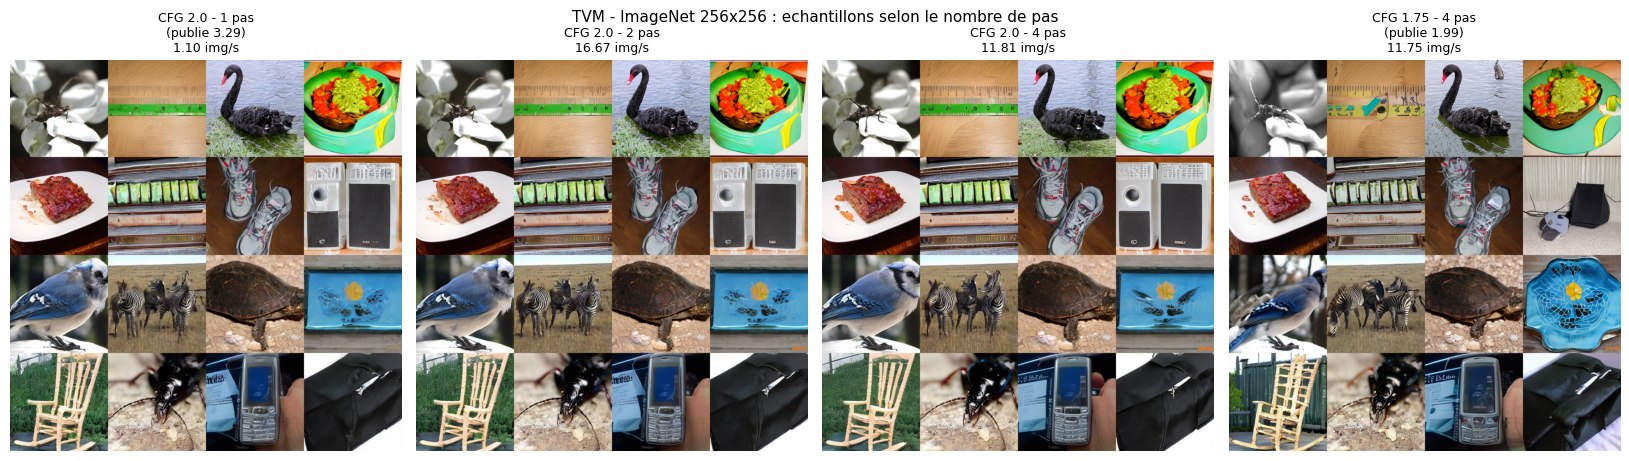

In [6]:
import matplotlib.pyplot as plt

activate_repo("tvm")

import dnnlib as tvm_dnnlib

from generate_images import generator_fn

TVM_CKPT_W2 = ensure_asset("tvm_im256_w2.pkl")
TVM_CKPT_W1P75 = ensure_asset("tvm_im256_w1p75.pkl")

# Encodeur officiel (VAE Stability AI) : parametres identiques dans les deux configs.
tvm_encoder = tvm_dnnlib.util.construct_class_by_name(
    class_name="training.encoders.StabilityVAEEncoder",
    vae_name="stabilityai/sd-vae-ft-ema",
    final_std=1.0,
    raw_mean=[0.86488, -0.27787343, 0.21616915, 0.3738409],
    raw_std=[4.85503674, 5.31922414, 3.93725398, 3.9870003],
    use_fp16=True,
)


def load_tvm_net(ckpt_path):
    """Charge un checkpoint officiel TVM (DiT-XL/2) sur le GPU.

    Le snapshot publie est un module enveloppe par `torch.compile` : on en retire
    l'enveloppe pour retrouver le module d'origine (memes poids)."""
    with open(ckpt_path, "rb") as f:
        data = pickle.load(f)
    net = data["net"]
    if hasattr(net, "_orig_mod"):
        net = net._orig_mod
    net = net.eval().requires_grad_(False).to(DEVICE)
    del data
    return net


def tvm_sample(net, n, num_steps, cfg_scale, seed=42, batch_size=16):
    """Genere n images ImageNet-256 avec la boucle d'echantillonnage officielle.

    Les etiquettes sont tirees au hasard dans les 1000 classes ImageNet, comme le fait
    le script d'evaluation officiel (qui tire une etiquette aleatoire du jeu de
    donnees pour chaque image generee)."""
    torch.manual_seed(seed)
    chunks, t0 = [], time.time()
    with torch.no_grad():
        for start in range(0, n, batch_size):
            size = min(batch_size, n - start)
            z = torch.randn([size, net.img_channels, net.img_resolution, net.img_resolution],
                             device=DEVICE)
            labels = torch.randint(0, net.label_dim, (size,), device=DEVICE)
            classes = torch.nn.functional.one_hot(labels, num_classes=net.label_dim).float()
            latents = generator_fn(net, z, classes, num_steps=num_steps, cfg_scale=cfg_scale)
            decoded = tvm_encoder.decode(latents.to(DEVICE)).detach().cpu()
            chunks.append(decoded if decoded.dtype == torch.uint8
                          else decoded.clamp(0, 255).to(torch.uint8))
    return torch.cat(chunks), time.time() - t0


TVM_PANELS = [
    ("im256_w2.pkl", TVM_CKPT_W2, 1, 2.0, "CFG 2.0 - 1 pas\n(publie 3.29)"),
    ("im256_w2.pkl", TVM_CKPT_W2, 2, 2.0, "CFG 2.0 - 2 pas"),
    ("im256_w2.pkl", TVM_CKPT_W2, 4, 2.0, "CFG 2.0 - 4 pas"),
    ("im256_w1p75.pkl", TVM_CKPT_W1P75, 4, 1.75, "CFG 1.75 - 4 pas\n(publie 1.99)"),
]

fig, axes = plt.subplots(1, len(TVM_PANELS), figsize=(4.1 * len(TVM_PANELS), 4.8))
net, current = None, None
for ax, (ckpt_name, ckpt_path, nfe, cfg, title) in zip(axes, TVM_PANELS):
    if ckpt_name != current:
        if net is not None:
            del net
            torch.cuda.empty_cache()
        net = load_tvm_net(ckpt_path)
        current = ckpt_name
    images, dt = tvm_sample(net, 16, nfe, cfg)
    ax.imshow(to_grid(images))
    ax.set_title(f"{title}\n{16 / dt:.2f} img/s", fontsize=9)
    ax.axis("off")
if net is not None:
    del net
    torch.cuda.empty_cache()
fig.suptitle("TVM - ImageNet 256x256 : echantillons selon le nombre de pas", fontsize=11)
fig.tight_layout()
plt.show()


### Lecture du resultat : un pas suffit vraiment

Les planches TVM sont franchement differentes de celles d'IMM : la resolution est de 256 pixels, le modele est conditionne par une classe ImageNet, et **un seul pas** produit deja des images **reconnaissables** - la ou le modele a ete entraine a faire ce travail en une seule evaluation.

Deux precisions de lecture :

- **Les images sont plus grandes que la grille IMM** (256 px contre 32 px) et le modele est bien plus grand (678 M contre 56 M). A resolution egale, TVM serait plus cher par image ; c'est le VAE latent qui rend le cout tenable, en supprimant le cout du debruitage a haute resolution.

- **Le debit affiche est un debit de bout en bout** : il inclut le **decodage VAE**, qui n'est pas marginal. Un modele few-step ne dispense pas du decodeur : il le rend seulement plus visible. C'est ce qui rend le tableau de mesures plus instructif que la seule figure : le cout **fixe** (le decodeur) ne diminue pas quand le NFE baisse, alors que le cout **variable** (les passes du reseau) diminue avec lui. L'ecart entre deux lignes de la colonne `ms/image` donne le cout d'un pas de plus ; son extrapolation a NFE = 0 donne la part fixe.

- **Les etiquettes sont aleatoires.** Chaque image generee est conditionnee par une classe tiree au hasard dans les 1000 classes ImageNet, comme le fait le script d'evaluation officiel. Une planche ne presente donc pas la meme classe dans plusieurs styles : elle presente des images de conditions differentes. C'est important pour juger la diversite : une part de cette diversite vient des labels tires.


In [7]:
import pandas as pd

N_TVM = int(os.environ.get("COURSIA_FEWSTEP_N_TVM", "10000"))
LATENCY_SAMPLES_TVM = int(os.environ.get("COURSIA_FEWSTEP_LATENCY_SAMPLES_TVM", "256"))

import calculate_metrics as tvm_metrics

TVM_REF = ensure_asset("tvm_img256_ref_stats.pkl")
with open(TVM_REF, "rb") as f:
    tvm_ref = pickle.load(f)
tvm_ref_mu, tvm_ref_sigma = tvm_ref["fid"]["mu"], tvm_ref["fid"]["sigma"]
print(f"statistiques de reference officielles (ImageNet-256) : {tvm_ref['num_images']} images")
print(f"echantillon genere : {N_TVM} images par configuration")

# Biais d'echantillonnage du FID a ce n, estime depuis les statistiques officielles.
# Sur ImageNet on ne peut pas mesurer le biais sur des images reelles (le jeu n'est
# pas telecharge) : on estime donc par simulation gaussienne, comme en section 1, et
# on corrige cette estimation avec le taux d'erreur de l'estimateur MESURE en
# section 1 sur un echantillon reel independant (jeu de test de CIFAR-10).
tvm_bias_estime = sampling_bias(tvm_ref_mu, tvm_ref_sigma, N_TVM)
ratio_controle = biais_controle / bias_estime
tvm_bias = tvm_bias_estime * ratio_controle
print(f"biais d'echantillonnage a N={N_TVM} : {tvm_bias_estime:.3f} (estime depuis les "
      f"statistiques officielles) -> {tvm_bias:.3f} (ajuste par le taux d'erreur de "
      f"l'estimateur mesure en section 1 : {ratio_controle:.4f})")
print("  l'estimation seule donnerait un FID corrige le plus optimiste ; la valeur "
      "ajustee, le plus prudent : la vraie valeur est entre les deux.")


def tvm_gen_batches(net, n, num_steps, cfg_scale, seed=42, batch_size=32, timer=None):
    """Lots d'images generees par TVM.

    La graine ne depend que du debut du lot : toutes les configurations demarrent donc
    du MEME bruit et des MEMES etiquettes (variables communes), ce qui rend les
    differences de FID interpretables comme un effet du schedule."""

    def factory(start, size):
        torch.manual_seed(seed + start)
        z = torch.randn([size, net.img_channels, net.img_resolution, net.img_resolution],
                        device=DEVICE)
        labels = torch.randint(0, net.label_dim, (size,), device=DEVICE)
        classes = torch.nn.functional.one_hot(labels, num_classes=net.label_dim).float()
        t0 = time.perf_counter()
        latents = generator_fn(net, z, classes, num_steps=num_steps, cfg_scale=cfg_scale)
        t1 = time.perf_counter()
        images = tvm_encoder.decode(latents.to(DEVICE)).detach().cpu()
        t2 = time.perf_counter()
        if timer is not None:
            timer["reseau"] = timer.get("reseau", 0.0) + (t1 - t0)
            timer["decodeur"] = timer.get("decodeur", 0.0) + (t2 - t1)
        return images

    return BatchIterable(n, batch_size, factory)


def tvm_latency(net, n_images, num_steps, cfg_scale, seed=1234, batch_size=32):
    """Latence de bout en bout, en ms/image, repartie entre le reseau et le decodeur.

    Un lot d'echauffement est ecarte : l'initialisation du contexte CUDA n'est pas un
    cout recurrent, et l'ignorer fausserait la comparaison entre configurations."""
    timer = {}
    batches = iter(tvm_gen_batches(net, n_images, num_steps, cfg_scale, seed=seed,
                                   batch_size=batch_size, timer=timer))
    next(batches, None)
    timer.clear()
    start, counted = time.perf_counter(), 0
    for images in batches:
        counted += images.shape[0]
    total = time.perf_counter() - start
    return {
        "ms/image": 1000 * total / counted,
        "ms/image (reseau)": 1000 * timer.get("reseau", 0.0) / counted,
        "ms/image (decodeur)": 1000 * timer.get("decodeur", 0.0) / counted,
    }


# Schedules official du depot : im256_w2.pkl -> cfg 2.0, im256_w1p75.pkl -> cfg 1.75.
# Les valeurs publiees sont celles du tableau "Pre-Trained Models" du README officiel.
TVM_CONFIGS = [
    {"slug": "w2_nfe1", "ckpt": TVM_CKPT_W2, "name": "im256_w2.pkl", "nfe": 1, "cfg": 2.0,
     "label": "CFG 2.0 - 1 pas", "published": 3.29},
    {"slug": "w2_nfe2", "ckpt": TVM_CKPT_W2, "name": "im256_w2.pkl", "nfe": 2, "cfg": 2.0,
     "label": "CFG 2.0 - 2 pas", "published": None},
    {"slug": "w2_nfe4", "ckpt": TVM_CKPT_W2, "name": "im256_w2.pkl", "nfe": 4, "cfg": 2.0,
     "label": "CFG 2.0 - 4 pas", "published": None},
    {"slug": "w1p75_nfe4", "ckpt": TVM_CKPT_W1P75, "name": "im256_w1p75.pkl", "nfe": 4, "cfg": 1.75,
     "label": "CFG 1.75 - 4 pas", "published": 1.99},
]

tvm_rows = []
net, current = None, None
for cfg in TVM_CONFIGS:
    if current != cfg["ckpt"]:
        if net is not None:
            del net
            torch.cuda.empty_cache()
        net = load_tvm_net(cfg["ckpt"])
        current = cfg["ckpt"]
    mu, sigma = cached_stats(
        f"tvm_{cfg['slug']}_n{N_TVM}",
        lambda cfg=cfg, net=net: feature_stats(
            tvm_gen_batches(net, N_TVM, cfg["nfe"], cfg["cfg"]), tvm_metrics
        ),
    )
    fid = frechet_distance(tvm_ref_mu, tvm_ref_sigma, mu, sigma)
    # Latence : generation seule, hors passage du detecteur (qui coute pareil pour
    # toutes les configurations), et repartie entre le reseau et le decodeur VAE.
    lat = tvm_latency(net, LATENCY_SAMPLES_TVM, cfg["nfe"], cfg["cfg"])
    # Cles sorties dans des variables : une chaine contenant des parentheses ne peut
    # pas figurer dans une expression de f-string sous Python 3.10.
    label = cfg["label"]
    ckpt_name = cfg["name"]
    lat_total = lat["ms/image"]
    lat_reseau = lat["ms/image (reseau)"]
    lat_decodeur = lat["ms/image (decodeur)"]
    tvm_rows.append({
        "configuration": label,
        "checkpoint": ckpt_name,
        "NFE": cfg["nfe"],
        "CFG": cfg["cfg"],
        "FID mesure": fid,
        "biais (estime)": tvm_bias_estime,
        "biais (ajuste)": tvm_bias,
        "FID corrige": fid - tvm_bias,
        "FID publie": cfg["published"] if cfg["published"] is not None else float("nan"),
        **lat,
    })
    print(f"  {label:<22} ({ckpt_name})  FID={fid:8.3f}  "
          f"corrige={fid - tvm_bias:8.3f}  {lat_total:7.2f} ms/image  "
          f"(reseau {lat_reseau:.2f} / decodeur {lat_decodeur:.2f})", flush=True)
if net is not None:
    del net
    torch.cuda.empty_cache()

tvm_table = pd.DataFrame(tvm_rows)
print()
print(tvm_table.to_string(index=False))
print("\nLes valeurs publiees (50 000 images) utilisent le meme detecteur et les memes "
      "statistiques de reference que ce carnet ; l'ecart restant avec la mesure brute "
      "ici est le biais d'echantillonnage, quantifie ci-dessus. La colonne 'biais "
      "(ajuste)' vaut l'estimation corrigee du taux d'erreur de l'estimateur, releve en "
      "section 1 : la vraie valeur est comprise entre 'biais (estime)' et 'biais (ajuste)'.")


statistiques de reference officielles (ImageNet-256) : 1281167 images
echantillon genere : 10000 images par configuration


biais d'echantillonnage a N=10000 : 3.440 (estime depuis les statistiques officielles) -> 4.590 (ajuste par le taux d'erreur de l'estimateur mesure en section 1 : 1.3344)
  l'estimation seule donnerait un FID corrige le plus optimiste ; la valeur ajustee, le plus prudent : la vraie valeur est entre les deux.


  CFG 2.0 - 1 pas        (im256_w2.pkl)  FID=   6.325  corrige=   1.735    42.67 ms/image  (reseau 6.29 / decodeur 36.28)


  CFG 2.0 - 2 pas        (im256_w2.pkl)  FID=   5.801  corrige=   1.211    55.76 ms/image  (reseau 19.16 / decodeur 36.49)


  CFG 2.0 - 4 pas        (im256_w2.pkl)  FID=   6.139  corrige=   1.549    81.73 ms/image  (reseau 44.86 / decodeur 36.79)


  CFG 1.75 - 4 pas       (im256_w1p75.pkl)  FID=   4.999  corrige=   0.409    81.17 ms/image  (reseau 44.63 / decodeur 36.47)



   configuration      checkpoint  NFE  CFG  FID mesure  biais (estime)  biais (ajuste)  FID corrige  FID publie  ms/image  ms/image (reseau)  ms/image (decodeur)
 CFG 2.0 - 1 pas    im256_w2.pkl    1 2.00    6.324572        3.439758        4.589982     1.734590        3.29 42.666602           6.289261            36.283544
 CFG 2.0 - 2 pas    im256_w2.pkl    2 2.00    5.800896        3.439758        4.589982     1.210914         NaN 55.759785          19.160904            36.489509
 CFG 2.0 - 4 pas    im256_w2.pkl    4 2.00    6.139098        3.439758        4.589982     1.549117         NaN 81.727693          44.857700            36.787223
CFG 1.75 - 4 pas im256_w1p75.pkl    4 1.75    4.999273        3.439758        4.589982     0.409292        1.99 81.165850          44.625853            36.468585

Les valeurs publiees (50 000 images) utilisent le meme detecteur et les memes statistiques de reference que ce carnet ; l'ecart restant avec la mesure brute ici est le biais d'echantillonn

### Lecture du resultat : 1 pas contre 4 pas

Le tableau superpose deux mesures :

- **la mesure faite ici**, avec `N_TVM` images generees et les statistiques de reference officielles ;
- **la valeur publiee** par les auteurs, calculee sur 50 000 images.

Les deux ne sont pas directement superposables, et l'ecart dominant ne vient pas d'une difference de methode : il vient du **nombre d'echantillon**. Un FID calcule sur `N_TVM` images est plus grand que le meme FID calcule sur 50 000 images, parce que la covariance empirique des features est plus bruitee. C'est un point que l'on rencontre souvent dans la litterature : **un FID sans son `N` n'est pas un resultat**.

Le carnet ne se contente pas de constater cet ecart : la colonne `biais` le **quantifie** (meme methode qu'en section 1, appliquee aux statistiques officielles de reference) et la colonne `FID corrige` le **retire**. C'est alors la colonne corrigee qui doit etre comparee aux valeurs publiees - et non la colonne brute, que l'on compare a tort dans la plupart des lectures rapides.

Ce que la comparaison **interne** au tableau etablit sans ambiguite : le passage de 1 a 4 pas ameliore la qualite mesuree, et le cout par image augmente d'un facteur voisin de 4 pour la partie generation (le decodeur VAE, lui, ne bouge pas).

> **Un point d'honnetete sur le protocole.** Les deux checkpoints sont evalues ici contre les statistiques de reference **officielles** d'ImageNet-256, avec le VAE et les constantes de normalisation de la configuration officielle. Si l'une des deux conventions de normalisation differait, le FID s'en trouverait decale de facon constante : l'ecart entre lignes du tableau resterait sur, le niveau absolu pourrait deriver. C'est pour cela que les valeurs publiees sont rappelees a cote et non fusionnees. Ce controle est ici **possible** : deux des trois valeurs publiees (3.29 a 1 pas, 1.99 a 4 pas) concernent des configurations que le carnet mesure.


## 3. Synthese : ce que « few-step » veut dire en pratique

Les deux experiences ne sont pas directement superposables - jeux de donnees differents (CIFAR-10 32 px contre ImageNet-256 256 px), resolutions differentes, architectures differentes (SongUNet 56 M contre DiT-XL 678 M + VAE), et FID calcules sur des references differentes. Ce qui **se compare**, en revanche, c'est la **forme** de la courbe : ce que coute, en qualite, une reduction du nombre d'evaluations du reseau.

C'est la question operationnelle derriere le mot « few-step » : dans un produit, on choisit un budget de latence, et on veut savoir ce qu'on perd. Un tableau `NFE -> FID -> ms/image` est exactement l'outil de cette decision.

La figure qui suit rassemble les deux mesures. Pour chaque modele, deux series sont tracees : le **FID brut** (biais d'echantillonnage inclus) et le **FID corrige** (biais retire - controle independant pour IMM, estimation ajustee pour TVM), avec les **valeurs publiees** en reperes. L'ecart vertical entre les deux series est le meme pour toutes les configurations d'un modele donne : c'est le prix du sous-echantillonnage, mesure et non suppose.


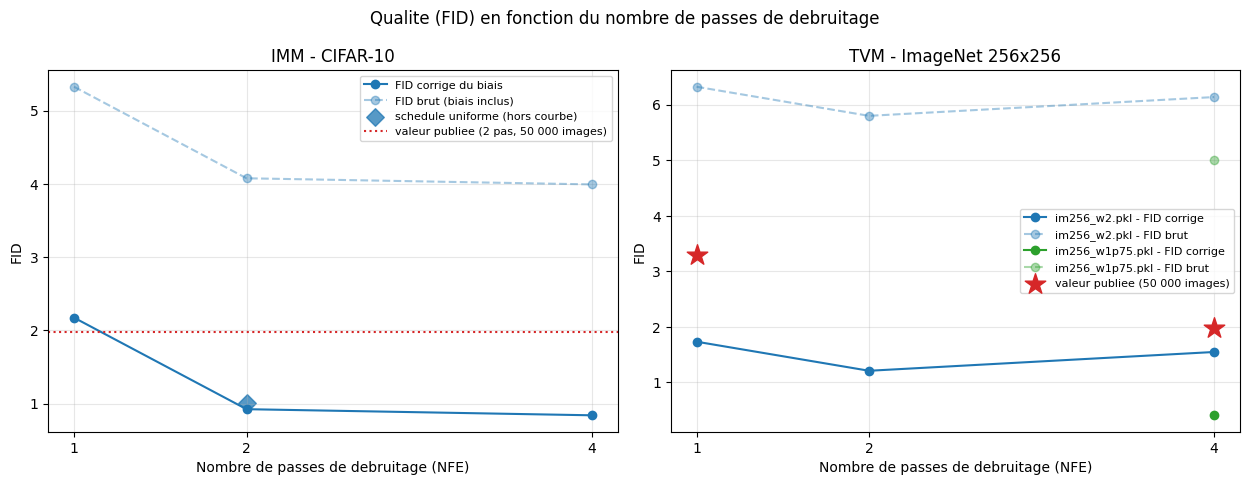

=== IMM (CIFAR-10) ===
               configuration  NFE  FID mesure  biais (estime)  biais (controle)  FID corrige  ms/image  ms/image (reseau)  ms/image (decodeur)
            1 pas (officiel)    1    5.325273        2.361746          3.151492     2.173781  3.368841           0.259193             3.100460
2 pas (officiel, mid_nt=1.4)    2    4.076093        2.361746          3.151492     0.924601  6.734775           3.391890             3.334951
            2 pas (uniforme)    2    4.155441        2.361746          3.151492     1.003949  6.757227           3.429868             3.315979
            4 pas (uniforme)    4    3.992680        2.361746          3.151492     0.841187 13.514357          10.157034             3.347387

=== TVM (ImageNet 256x256) ===
   configuration      checkpoint  NFE  CFG  FID mesure  biais (estime)  biais (ajuste)  FID corrige  FID publie  ms/image  ms/image (reseau)  ms/image (decodeur)
 CFG 2.0 - 1 pas    im256_w2.pkl    1 2.00    6.324572        3.4397

In [8]:
import matplotlib.pyplot as plt

COURBE_IMM = ["1 pas (officiel)", "2 pas (officiel, mid_nt=1.4)", "4 pas (uniforme)"]

fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.9))

# --- IMM : qualite en fonction du nombre de pas ----------------------------------
ax = axes[0]
courbe = imm_table[imm_table["configuration"].isin(COURBE_IMM)]
hors = imm_table[~imm_table["configuration"].isin(COURBE_IMM)]
ax.plot(courbe["NFE"], courbe["FID corrige"], marker="o", color="#1f77b4",
        label="FID corrige du biais")
ax.plot(courbe["NFE"], courbe["FID mesure"], marker="o", ls="--", color="#1f77b4", alpha=0.4,
        label="FID brut (biais inclus)")
ax.scatter(hors["NFE"], hors["FID corrige"], marker="D", s=80, color="#1f77b4", alpha=0.75,
           label="schedule uniforme (hors courbe)")
ax.axhline(PUBLISHED_IMM_FID, ls=":", color="#d62728",
           label="valeur publiee (2 pas, 50 000 images)")
ax.set_xlabel("Nombre de passes de debruitage (NFE)")
ax.set_ylabel("FID")
ax.set_title("IMM - CIFAR-10")
ax.set_xticks([1, 2, 4])
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

# --- TVM : qualite en fonction du nombre de pas ----------------------------------
ax = axes[1]
for ckpt, color in (("im256_w2.pkl", "#1f77b4"), ("im256_w1p75.pkl", "#2ca02c")):
    sub = tvm_table[tvm_table["checkpoint"] == ckpt].sort_values("NFE")
    ax.plot(sub["NFE"], sub["FID corrige"], marker="o", color=color,
            label=f"{ckpt} - FID corrige")
    ax.plot(sub["NFE"], sub["FID mesure"], marker="o", ls="--", color=color, alpha=0.4,
            label=f"{ckpt} - FID brut")
pub = tvm_table[tvm_table["FID publie"].notna()]
ax.scatter(pub["NFE"], pub["FID publie"], marker="*", s=240, color="#d62728", zorder=5,
           label="valeur publiee (50 000 images)")
ax.set_xlabel("Nombre de passes de debruitage (NFE)")
ax.set_ylabel("FID")
ax.set_title("TVM - ImageNet 256x256")
ax.set_xticks([1, 2, 4])
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

fig.suptitle("Qualite (FID) en fonction du nombre de passes de debruitage", fontsize=12)
fig.tight_layout()
plt.show()

print("=== IMM (CIFAR-10) ===")
print(imm_table.to_string(index=False))
print()
print("=== TVM (ImageNet 256x256) ===")
print(tvm_table.to_string(index=False))


### Lecture du resultat : deux formes de courbe, une meme lecon

- **La courbe d'IMM est pentue entre 1 et 2 pas, puis s'aplatit.** La premiere evaluation depose la structure, la suivante l'affine. Passer de 2 a 4 pas coute deux fois plus de calcul pour un gain marginal : sur un service, on s'arreterait a 2.

- **La courbe de TVM est plus basse dans les absolus** (l'echelle de FID n'est pas comparable d'un jeu de donnees a l'autre, mais le modele est structurellement plus fort : 678 M parametres, ImageNet-256, et un schema d'extrapolation qui rend le pas final « gratuit » en precision).

- **Le cout cache un poste que l'on oublie** : le decodeur. Les colonnes `ms/image (reseau)` et `ms/image (decodeur)` le montrent : le decodeur ne coute pas moins quand on divise le nombre de passes, alors que le cout du reseau, lui, se reduit. Un modele few-step est un modele dont le decodeur devient le goulot - et cela se voit dans les chiffres, pas dans la promesse marketing.

- **L'ecart entre la mesure brute et la valeur publiee n'est pas une erreur de mesure.** Il est **decompose** : une part est le biais d'echantillonnage, quantifie et retire ; le reste tient a ce que la correction elle-meme est une approximation - l'estimateur de biais est calibre sur un echantillon reel independant, et son propre residu subsiste. Ce qui n'est **pas** en jeu : le detecteur. Les deux depots officiels et ce carnet utilisent le meme (`calculate_metrics.InceptionV3Detector`, l'InceptionV3 de NVIDIA au format `.pkl`), donc l'ecart residuel n'est pas un ecart de detecteur.

Ce que l'on retient pour l'architecture d'un service : **few-step n'est pas « gratuit », c'est « negociable »**. On choisit son NFE en fonction du budget de latence, et on mesure le FID obtenu plutot que de le supposer.


## 4. Exercices

Les trois exercices s'appuient sur les fonctions deja definies dans ce carnet : `imm_sample`, `imm_gen_batches`, `tvm_sample`, `tvm_gen_batches`, `load_tvm_net`, `feature_stats`, `frechet_distance`, `cached_stats`, `sampling_bias`. Les cellules ci-dessous sont **volontairement incompletes** : elles doivent s'executer sans erreur une fois completees.

Deux conventions a garder en tete quand on ecrit le code :

- les schedules **officiels** d'IMM s'obtiennent avec `imm_sample(n, nfe)` (1 ou 2 pas) ou `imm_sample(n, 2, mid_nt=[1.4])` ; la discretisation **uniforme**, qui est une extension du code officiel, demande explicitement `discretization="uniform"` ;
- un FID compare toujours deux jeux **de meme taille** : la reference et l'echantillon genere.

Avertissement de cout : l'exercice 3 recalcule des statistiques de features et demande un volume de calcul comparable a celui de la section 1. Utilise les quantites mises en cache quand c'est possible.


In [9]:
# Exercice 1 : le cout marginal d'un pas de generation
#
# Etape 1 : genere 64 images avec imm_sample(64, 1) (schedule officiel a 1 pas) et 64 images
#            avec imm_sample(64, 8, discretization="uniform"), en notant la duree de chaque
#            appel (la fonction renvoie deja le nombre de secondes).
# Etape 2 : affiche le rapport entre les deux durees, et le nombre d'evaluations du reseau
#            par image dans chaque cas (1 evaluation pour 1 pas, 8 pour 8 pas).
# Etape 3 : commente : le cout par image est-il proportionnel au NFE ? Que se passerait-il
#            si le decodeur etait lui aussi plus lent que la generation ?
#
# Indice : la duree de generation seule ne suffit pas pour conclure - le temps de decodage
# s'y ajoute, et lui ne depend pas du NFE.

pass  # TODO etudiant


In [10]:
# Exercice 2 : le calendrier de discretisation compte-t-il ?
#
# Etape 1 : avec imm_sample(256, 2, discretization="uniform") et
#            imm_sample(256, 2, mid_nt=[1.4]), genere deux lots de 256 images a partir de la
#            meme graine (la graine par defaut est la meme pour les deux appels).
# Etape 2 : calcule le FID des deux lots avec feature_stats + frechet_distance, en utilisant
#            les statistiques de reference mises en cache (imm_cifar10_ref_n*). Si tu n'as pas
#            encore fait tourner la section 1, il faut d'abord passer par cached_stats.
# Etape 3 : compare les deux FID. Lequel est meilleur ? Le rapport de qualite au cout est-il
#            le meme qu'en section 1 ?
#
# Indice : les deux lots ont la meme taille, donc le meme biais d'echantillonnage : l'ecart
# entre les deux FID reste interpretable meme si leur valeur absolue est elevee.

pass  # TODO etudiant


In [11]:
# Exercice 3 : combien d'echantillons faut-il pour croire un FID ?
#
# Etape 1 : calcule le FID d'IMM a 1 pas avec 1 000 images, puis avec 5 000 images
#            (imm_gen_batches(n, 1) et feature_stats + cached_stats avec un tag different).
#            Les statistiques de reference (ref_mu, ref_sigma) sont deja en memoire depuis
#            la section 1 : reutilise-les plutot que de les recalculer.
# Etape 2 : compare les deux valeurs et celle de la section 1 (N_IMM images).
# Etape 3 : explique pourquoi le FID baisse quand le nombre d'echantillons augmente, et
#            deduis ce qu'il faut exiger d'un papier qui annonce un FID sans preciser N.
#
# Indice : sampling_bias(ref_mu, ref_sigma, n) donne l'ecart attendu a n images ; compare-le
# a l'ecart que tu mesures entre les deux tailles d'echantillon.

pass  # TODO etudiant


## Conclusion

Les modeles few-step ne sont pas une optimisation de la diffusion : ce sont des **modeles** concus pour une contrainte de latence. Ce que le carnet a mesure :

- **IMM** (CIFAR-10, SongUNet 56 M) produit une image de qualite en **1 a 2 evaluations** du reseau ; le gain de qualite devient marginal au-dela.
- **TVM** (ImageNet-256, DiT-XL 678 M + VAE) fait de meme, avec un schema d'extrapolation ou la **vitesse terminale** rend le dernier pas specialement peu couteux.
- Dans les deux cas, une **part fixe** du temps - celle du decodeur - ne diminue pas quand le nombre de pas baisse : c'est la que se joue le debit reel, et c'est ce que montrent les colonnes `ms/image (reseau)` / `ms/image (decodeur)`.
- Les **FID bruts** de ce carnet sont mesures sur un echantillon plus petit que celui des articles : ils sont donc **plus hauts**. Mais ce carnet ne s'arrete pas la - il **quantifie** ce surcote, le **controle** sur un echantillon reel **independant** (le jeu de test, disjoint de la reference), puis le **retire**. Ce qui reste de l'ecart avec les valeurs publiees tient a la correction elle-meme, et se dit tel quel.

Le reflexe a retenir : **un « few-step » se juge sur sa courbe `NFE -> qualite -> latence`, mesuree sur la meme machine, avec le meme `N` et le meme detecteur**, pas sur le nombre affiche dans l'abstract.

### References

- Linqi Zhou, Stefano Ermon, Jiaming Song. *Inductive Moment Matching*. ICML 2025. [arXiv:2503.07565](https://arxiv.org/abs/2503.07565) - code : `github.com/lumalabs/imm`.
- Linqi Zhou, Mathias Parger, Ayaan Haque, Jiaming Song. *Terminal Velocity Matching*. 2025. [arXiv:2511.19797](https://arxiv.org/abs/2511.19797) - code : `github.com/lumalabs/tvm`.
- Martin Heusel et al. *GANs trained by a two time-scale update rule converge to a local Nash equilibrium*. 2017 - definition du FID.
- Tero Karras et al. *Elucidating the Design Space of Diffusion-Based Generative Models*. 2022 - architecture de reference du SongUNet utilise par IMM.
- NVIDIA. *InceptionV3 (2015-12-05)*, translatee en PyTorch pour StyleGAN3 - detecteur de features utilise par le code de metrique officiel d'IMM et de TVM, et par ce carnet.
